# Simple neural-network baseline

## 1. Imports

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from kaggle_metric import score

## 2. Read the training data and feature tables

In [2]:
PROJECT_ROOT = Path.cwd()
KERNEL = PROJECT_ROOT / 'data' / 'kernel'
EXTENDED = PROJECT_ROOT / 'data' / 'extended'

train = pd.read_csv(KERNEL / 'Unit_commitment_decisions.csv')
train['starttime'] = pd.to_datetime(train['starttime'], utc=True).dt.tz_localize(None)
target_columns = [c for c in train.columns if c.startswith('result_committed_')]

def read_time_table(path):
    table = pd.read_csv(path)
    table['date'] = pd.to_datetime(table['date'], utc=True).dt.tz_localize(None)
    return table.set_index('date').sort_index()

price = read_time_table(KERNEL / 'Historical_day_ahead_price_2015_2025.csv')
inflow = read_time_table(KERNEL / 'Historical_inflow_1958_2025.csv')
volume = read_time_table(KERNEL / 'Historical_volume_2015_2024.csv')
water_value = read_time_table(KERNEL / 'Synthetic_water_value_2015_2024.csv')
min_volume = read_time_table(EXTENDED / 'Constraint_min_volume.csv')
min_flow = read_time_table(EXTENDED / 'Constraint_min_flow.csv')

print('Training cases:', len(train))
print('Targets:', len(target_columns))

Training cases: 2922
Targets: 2352


## 3. Build simple features

We retain all 168 known hourly prices. Inflow and constraints use week-level summaries; storage and water values use the start/end of the window. `Run No` and `total_calculation_time` are excluded.

In [3]:
HORIZON = 168

def weekly_window(table, starts):
    offsets = np.arange(HORIZON, dtype='timedelta64[h]')
    timestamps = starts.to_numpy(dtype='datetime64[ns]')[:, None] + offsets
    values = table.reindex(pd.DatetimeIndex(timestamps.ravel())).to_numpy()
    return values.reshape(len(starts), HORIZON, table.shape[1])

def daily_values(table, dates):
    return table.reindex(pd.DatetimeIndex(dates)).to_numpy()

def make_features(cases):
    starts = cases['starttime']
    price_week = weekly_window(price, starts)[:, :, 0]
    inflow_week = weekly_window(inflow, starts)
    constraints_week = np.concatenate([weekly_window(min_volume, starts), weekly_window(min_flow, starts)], axis=2)
    calendar = pd.DataFrame({'month': starts.dt.month, 'day_of_year': starts.dt.dayofyear, 'day_of_week': starts.dt.dayofweek, 'is_weekend': (starts.dt.dayofweek >= 5).astype(int)}, index=cases.index)
    price_features = pd.DataFrame(price_week, index=cases.index, columns=[f'price_t{hour}' for hour in range(HORIZON)])
    inflow_features = pd.DataFrame(
        np.concatenate([inflow_week.mean(axis=1), inflow_week.min(axis=1), inflow_week.max(axis=1)], axis=1), index=cases.index,
        columns=[f'inflow_mean_{name}' for name in inflow.columns] + [f'inflow_min_{name}' for name in inflow.columns] + [f'inflow_max_{name}' for name in inflow.columns],
    )
    constraint_names = [*min_volume.columns, *min_flow.columns]
    constraint_features = pd.DataFrame(
        np.concatenate([constraints_week.max(axis=1), (constraints_week > 0).mean(axis=1)], axis=1), index=cases.index,
        columns=[f'constraint_max_{name}' for name in constraint_names] + [f'constraint_share_active_{name}' for name in constraint_names],
    )
    volume_features = pd.DataFrame(daily_values(volume, starts), index=cases.index, columns=[f'volume_{name}' for name in volume.columns])
    water_start = pd.DataFrame(daily_values(water_value, starts), index=cases.index, columns=[f'water_start_{name}' for name in water_value.columns])
    water_end = pd.DataFrame(daily_values(water_value, starts + pd.Timedelta(days=7)), index=cases.index, columns=[f'water_end_{name}' for name in water_value.columns])
    features = pd.concat([calendar, price_features, inflow_features, constraint_features, volume_features, water_start, water_end], axis=1)
    return features


## 4. Create inputs and make a time-based split

In [4]:
X = make_features(train)
y = train[target_columns]
print('Feature table shape:', X.shape)

validation_start = pd.Timestamp('2022-01-01')
validation_end = pd.Timestamp('2023-01-01')
train_mask = train['starttime'] < validation_start - pd.Timedelta(days=7)
validation_mask = (train['starttime'] >= validation_start) & (train['starttime'] < validation_end)
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_valid, y_valid = X.loc[validation_mask], y.loc[validation_mask]
print('Train cases:', len(X_train))
print('Validation cases:', len(X_valid))

Feature table shape: (2922, 295)
Train cases: 2550
Validation cases: 365


## 5. Scale the features

The scaler is fitted on training cases only, then reused for validation.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

## 6. Train one neural network

The fitted network has hidden layers `(256, 128)`. Early stopping uses
the estimator's internal validation subset of training cases; the external
2022 validation year is reserved for scoring and interpretation.


In [6]:
model = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    max_iter=2000,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=50,
    tol=1e-5,
    learning_rate_init=0.001,
    alpha=0.0001,
    random_state=67,
    verbose=False,
)

model.fit(X_train_scaled, y_train)

print("Epochs used:", model.n_iter_)

Epochs used: 145


## 7. Evaluate with the official metric

In [7]:
valid_probabilities = model.predict_proba(X_valid_scaled)
valid_submission = pd.DataFrame(valid_probabilities, columns=target_columns)
valid_submission.insert(0, 'Run No', train.loc[validation_mask, 'Run No'].to_numpy())
valid_solution = train.loc[validation_mask, ['Run No', *target_columns]]

auc = score(valid_solution, valid_submission)
print(f'2022 validation micro ROC-AUC: {auc:.4f}')

2022 validation micro ROC-AUC: 0.9240


## 8. Model interpretation: permutation importance

We compare three input groups by shuffling each group between 2022 validation
cases and measuring the decrease in micro ROC-AUC. The model stays fixed.
A larger decrease means greater reliance on that group. Columns in each
group are shuffled together to preserve their within-week relationships.
This is one shuffle per group, so the result is illustrative; it does not
show causality or the direction of an effect.


Initial water values        0.018562
Hourly prices               0.172482
End-of-week water values    0.368787
Name: Decrease in validation ROC-AUC, dtype: float64


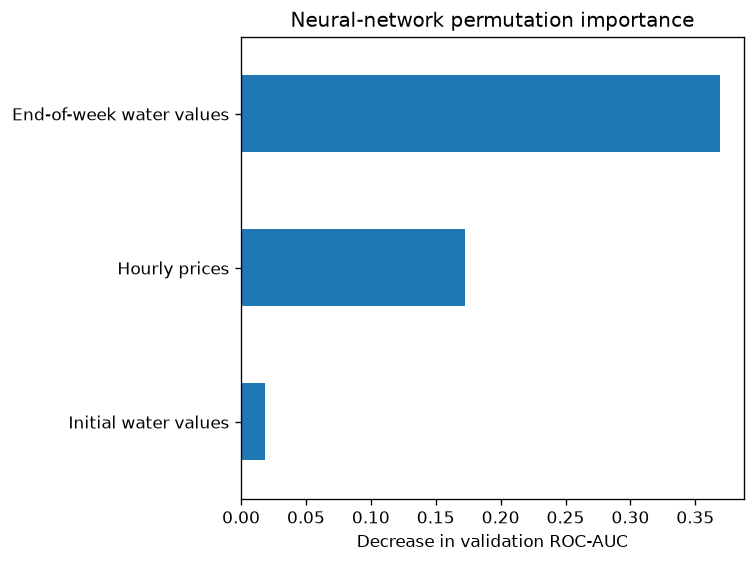

In [8]:
from sklearn.metrics import roc_auc_score

# Shuffle one input group at a time, keeping the trained network fixed.
groups = {'Hourly prices': 'price_t',
          'Initial water values': 'water_start_',
          'End-of-week water values': 'water_end_'}
permutation = np.random.default_rng(42).permutation(len(X_valid))
importance = {}
for name, prefix in groups.items():
    columns = X_valid.columns.str.startswith(prefix)
    shuffled = X_valid_scaled.copy()
    shuffled[:, columns] = X_valid_scaled[permutation][:, columns]
    probabilities = model.predict_proba(shuffled)
    importance[name] = auc - roc_auc_score(y_valid, probabilities, average='micro')

importance = pd.Series(importance).sort_values()
print(importance.rename('Decrease in validation ROC-AUC'))
importance.plot.barh(xlabel='Decrease in validation ROC-AUC',
                     title='Neural-network permutation importance')
plt.tight_layout()
plt.show()
